# 02 · Default prediction

**Question:** how well can next-month default be predicted from six months of history?

Three models are compared on the same stratified 80/20 split:
logistic regression, random forest and XGBoost. All metrics below come from the held-out
20% test set. Sex and marital status are excluded from the features. Precision and recall are reported at a 0.5 cut-off and at the cut-off that
maximises F1 on the training folds.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG = ROOT / "images"
SEED = 42

df = pd.read_csv(ROOT / "data" / "clean" / "credit_card_clients_clean.csv")
TARGET = "DEFAULT_NEXT_MONTH"
# SEX is left out because UK and EU law bars pricing credit on it.
# MARRIAGE is left out as a fairness precaution.
EXCLUDED = ["ID", TARGET, "SEX", "MARRIAGE"]
FEATURES = [c for c in df.columns if c not in EXCLUDED]
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train {len(X_train):,} rows, test {len(X_test):,} rows, {len(FEATURES)} features")
print(f"Default rate train {y_train.mean():.1%}, test {y_test.mean():.1%}")

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train 24,000 rows, test 6,000 rows, 25 features
Default rate train 22.1%, test 22.1%


In [2]:
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=20,
                                            n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(n_estimators=400, learning_rate=0.03, max_depth=4,
                             subsample=0.8, colsample_bytree=0.8, eval_metric="auc",
                             random_state=SEED, n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows, test_probs = [], {}
for name, model in models.items():
    # Choose the F1-best threshold on out-of-fold training predictions (no test leakage).
    oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    p, r, t = precision_recall_curve(y_train, oof)
    f1 = 2 * p * r / (p + r + 1e-12)
    best_t = t[np.argmax(f1[:-1])]

    model.fit(X_train, y_train)
    prob = model.predict_proba(X_test)[:, 1]
    test_probs[name] = prob
    for label, cut in [("0.50", 0.5), (f"{best_t:.2f} (F1-best)", best_t)]:
        pred = (prob >= cut).astype(int)
        rows.append({"model": name, "threshold": label,
                     "roc_auc": roc_auc_score(y_test, prob),
                     "precision": precision_score(y_test, pred),
                     "recall": recall_score(y_test, pred),
                     "f1": f1_score(y_test, pred)})

results = pd.DataFrame(rows).round(3)
results

,model,threshold,roc_auc,precision,recall,f1
0,Logistic regression,0.50,0.746,0.644,0.300,0.409
1,Logistic regression,0.29 (F1-best),0.746,0.492,0.549,0.519
2,Random forest,0.50,0.775,0.654,0.358,0.463
3,Random forest,0.27 (F1-best),0.775,0.500,0.586,0.539
4,XGBoost,0.50,0.781,0.669,0.361,0.469
5,XGBoost,0.28 (F1-best),0.781,0.517,0.567,0.541


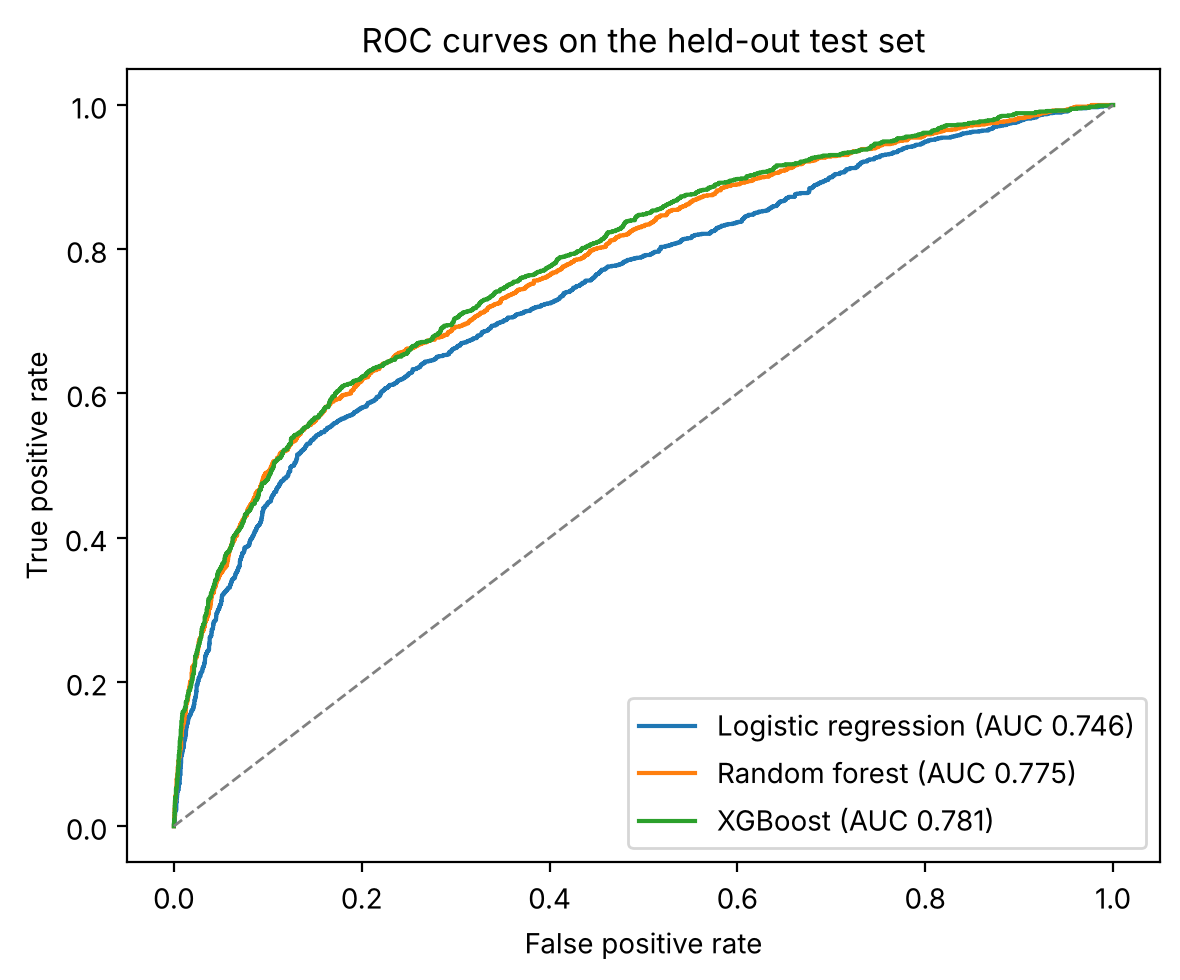

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, prob in test_probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, prob):.3f})")
ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1)
ax.set(xlabel="False positive rate", ylabel="True positive rate",
       title="ROC curves on the held-out test set")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(IMG / "roc_curves.png", dpi=150)
plt.show()

## Explaining the XGBoost model with SHAP

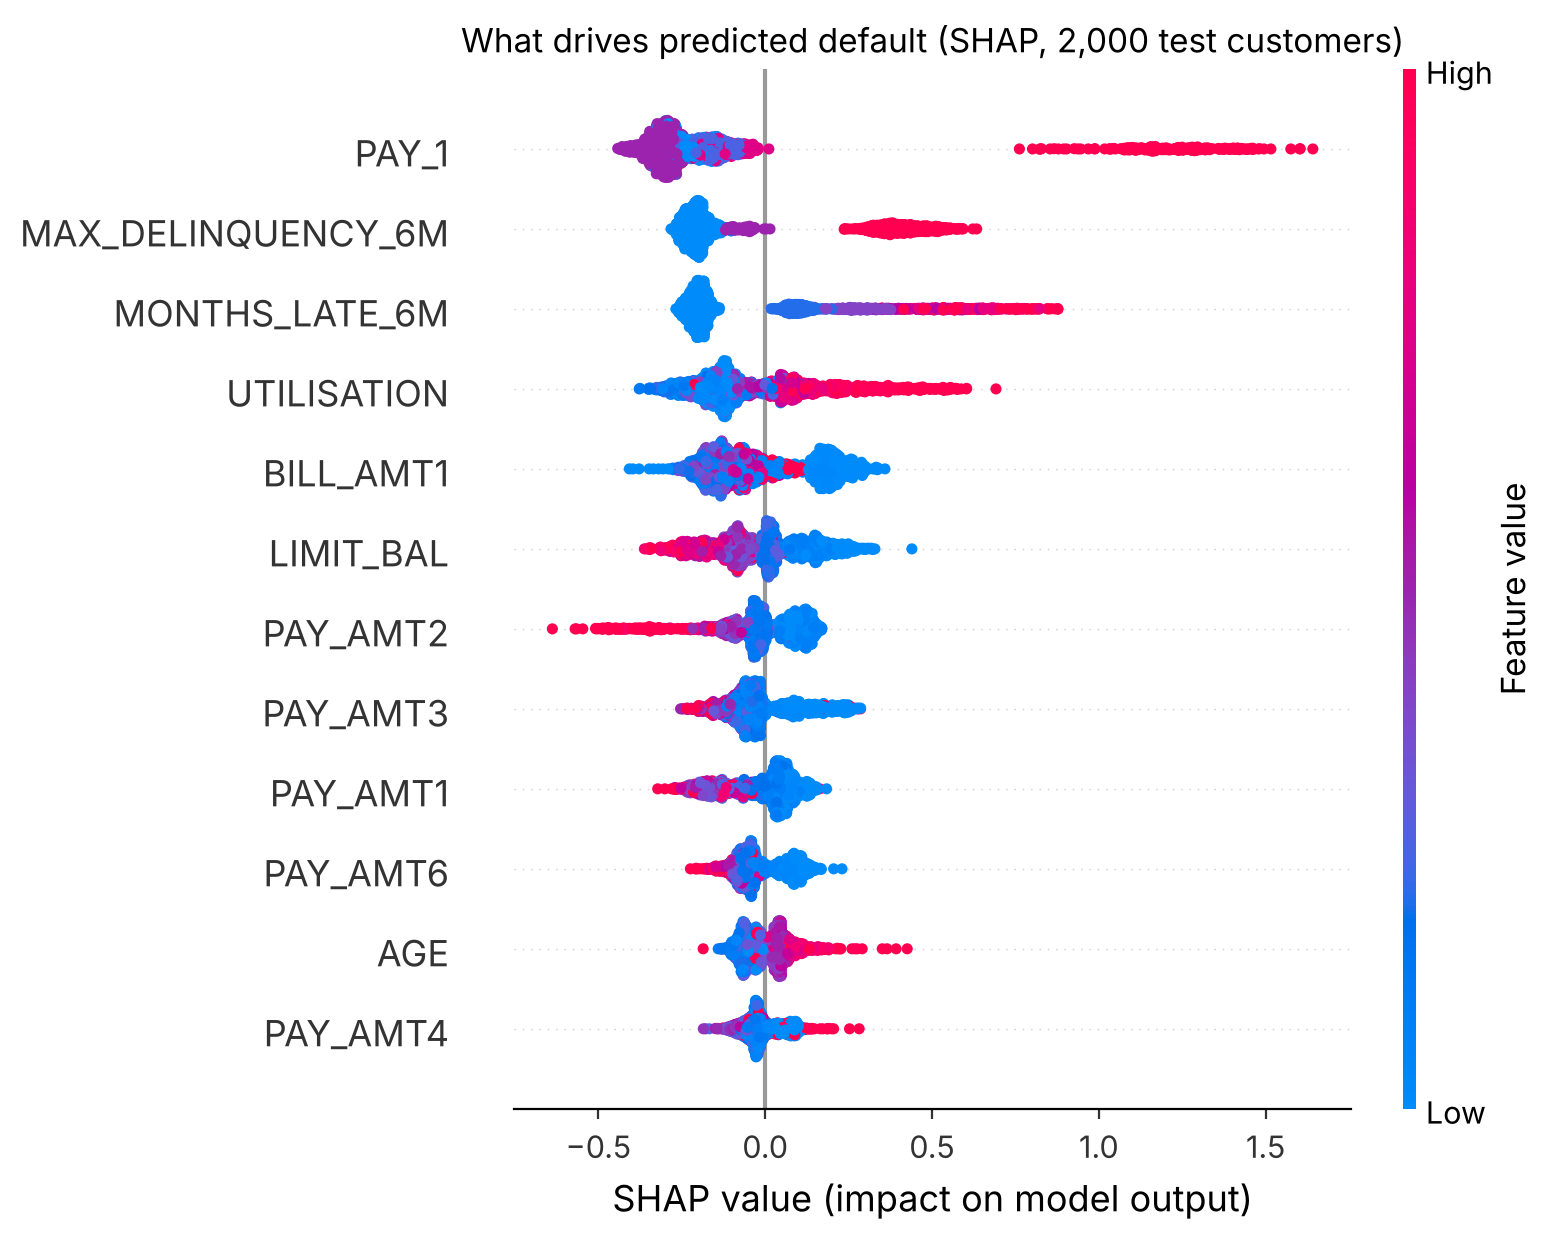

In [4]:
xgb = models["XGBoost"]
explainer = shap.TreeExplainer(xgb)
sample = X_test.sample(2000, random_state=SEED)
shap_values = explainer.shap_values(sample)
shap.summary_plot(shap_values, sample, max_display=12, show=False)
plt.title("What drives predicted default (SHAP, 2,000 test customers)")
plt.tight_layout()
plt.savefig(IMG / "shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
importance = (pd.Series(np.abs(shap_values).mean(axis=0), index=sample.columns)
                .sort_values(ascending=False))
importance.head(8).round(4)

PAY_1                 0.3469
MAX_DELINQUENCY_6M    0.2578
MONTHS_LATE_6M        0.2370
UTILISATION           0.1574
BILL_AMT1             0.1381
LIMIT_BAL             0.1135
PAY_AMT2              0.0912
PAY_AMT3              0.0848
dtype: float32

## Score the whole portfolio for segmentation
Every customer gets an out-of-fold XGBoost probability of default (5-fold), so no
customer is scored by a model that saw their own outcome.

In [6]:
pd_oof = cross_val_predict(models["XGBoost"], X, y, cv=cv, method="predict_proba")[:, 1]
out = ROOT / "data" / "output"
out.mkdir(parents=True, exist_ok=True)
pd.DataFrame({"ID": df["ID"], "PD_SCORE": pd_oof.round(5)}).to_csv(out / "pd_scores.csv", index=False)
results.to_csv(out / "model_results.csv", index=False)
print(f"Out-of-fold AUC on all 30,000 customers: {roc_auc_score(y, pd_oof):.3f}")

Out-of-fold AUC on all 30,000 customers: 0.786
